# Visualización de datos

El objetivo de esta sección es responder, mediante visualizaciones, las preguntas de investigación planteadas al inicio del proyecto:

1. **¿Que tan confiable es el promedio de la calificaión de una película según cuantas calificaciones tiene?**
Para validar como el número de calificaciones influye en la calificación promedio
2. **¿Cómo se distribuyen las calificaciones?** Para conocer qué valores son los más frecuentes y qué tan concentradas o dispersas están las evaluaciones de los usuarios.
2. **¿Que genero es el más frecuente del catálogo?**
Para analizar la composición del catálogo
3. **¿Qué géneros reciben mejores calificaciones?** Para comparar el desempeño promedio de los distintos géneros del catálogo.
4. **¿Cómo se distribuye la calificación promedio por género?** Para analizar si el la calificación otorgada a las peliculas esta relacionada con el género
5. **¿Las películas antiguas tienen mejores calificaciones que las recientes?** Para contrastar la valoración de películas de distintas épocas de estreno.
6. **¿Cómo se distribuye el número de calificaciones?** Para observar el número promedio de calificacones por película
7. **¿Cuál es el top 10 de las películas mejores calificadas?** 


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
import shutil
import warnings
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Localizar la raíz del proyecto.
cwd = Path.cwd()
candidates = [cwd, *cwd.parents]
PROJECT_ROOT = next(
    (p for p in candidates if (p / "data").exists() and (p / "notebooks").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se localizó la raíz del proyecto. Ejecuta el notebook desde la carpeta "
        "'notebooks' o ajusta PROJECT_ROOT manualmente."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "ml-32m"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DIAGNOSTICS_DIR = PROCESSED_DIR / "diagnostics"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Datos originales: {RAW_DIR}")
print(f"Datos procesados: {PROCESSED_DIR}")

Raíz del proyecto: c:\Users\igpea\OneDrive\Documents\Diplomado\Proyecto_Integrador_M1
Datos originales: c:\Users\igpea\OneDrive\Documents\Diplomado\Proyecto_Integrador_M1\data\raw\ml-32m
Datos procesados: c:\Users\igpea\OneDrive\Documents\Diplomado\Proyecto_Integrador_M1\data\processed


In [4]:

FILES = {
    "movies_genres": PROCESSED_DIR / "movie_genres.csv",
    "ratings": RAW_DIR / "ratings.csv",
    "movies_consolidated": PROCESSED_DIR / "movies_consolidated.csv",
    "genre_frequency": PROCESSED_DIR / "genre_frequency.csv"
}

missing_files = [name for name, path in FILES.items() if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"No se encontraron estos archivos: {missing_files}")

movies_consolidated = pd.read_csv(FILES["movies_consolidated"],
                                  dtype={"moveId":"str","year":"Int64", "tmdbId":"Int64"})
ratings = pd.read_csv(FILES["ratings"])
movies_genres=pd.read_csv(FILES["movies_genres"])
genre_frequency = pd.read_csv(FILES["genre_frequency"])

 ### ¿Que tan confiable es el promedio de la calificaión de una película según cuantas calificaciones tiene?

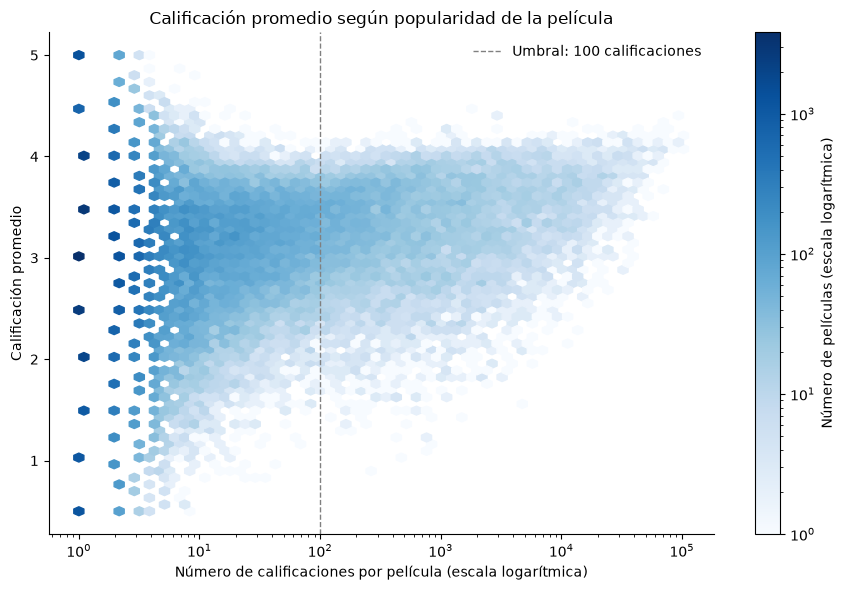

In [6]:
d = movies_consolidated.dropna(subset=["rating_mean"])

fig, ax = plt.subplots(figsize=(9, 6))
hb = ax.hexbin(d["rating_count"], d["rating_mean"], xscale="log",
               gridsize=60, bins="log", cmap="Blues", mincnt=1)
ax.axvline(100, color="gray", linestyle="--", linewidth=1, label="Umbral: 100 calificaciones")
fig.colorbar(hb, ax=ax, label="Número de películas (escala logarítmica)")

ax.set_xlabel("Número de calificaciones por película (escala logarítmica)")
ax.set_ylabel("Calificación promedio")
ax.set_title("Calificación promedio según popularidad de la película")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Interpretación.** El gráfico relaciona el número de calificaciones de cada película con su calificación promedio. Las películas con pocas calificaciones presentan promedios muy dispersos, mientras que a medida que aumenta el número de calificaciones los promedios se concentran en un rango más estrecho. Además, el límite inferior de los promedios sube con la popularidad: las películas muy calificadas rara vez tienen promedios bajos. 

Esto es relevante porque el promedio de una película con pocas calificaciones es poco confiable: unas cuantas calificaciones bastan para moverlo. Por eso, al comparar géneros y décadas **ponderamos por el número de calificaciones** y, en el análisis de dispersión por género, **excluimos las películas con menos de 100 calificaciones** 

**Limitaciones.** El gráfico es descriptivo y no permite concluir que las películas más populares sean mejores

### ¿Cómo se distribuyen las calificaciones?

Para responder esta pregunta analizamos la tabla `ratings`, donde cada fila es una calificación emitida por un usuario a una película. Como la calificación es una **variable categórica ordinal** (toma valores ordenados de 0.5 a 5 en pasos de 0.5), la representamos con un **gráfico de barras** que muestra la frecuencia de cada valor. Así vemos cuáles son los más comunes y qué tan concentradas o dispersas están las evaluaciones.

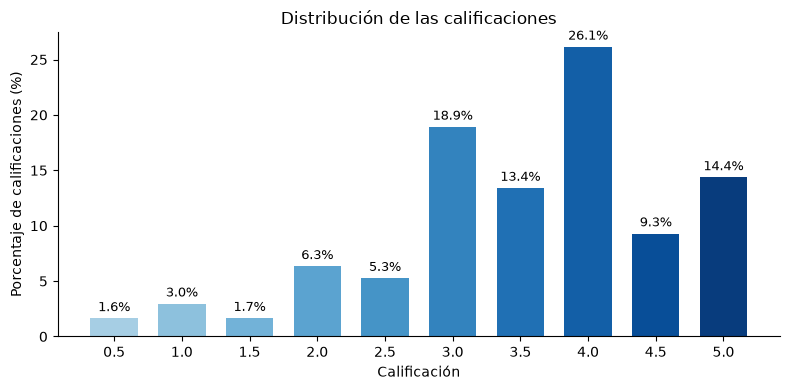

In [7]:
counts_ratings=ratings["rating"].value_counts().sort_index()
pct = counts_ratings / counts_ratings.sum() * 100

fig, ax = plt.subplots(figsize=(8, 4))

colores = plt.cm.Blues(np.linspace(0.35, 0.95, len(pct)))
barras = ax.bar(counts_ratings.index.astype(str), pct, width=0.7, color=colores)
ax.bar_label(barras, labels=[f"{p:.1f}%" for p in pct], padding=3, fontsize=9)

ax.set_xlabel("Calificación")
ax.set_ylabel("Porcentaje de calificaciones (%)")
ax.set_title("Distribución de las calificaciones")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


In [8]:
print((ratings["rating"] >= 3.5).mean() * 100)
print((ratings["rating"] < 3).mean() * 100)
print(ratings["rating"].median())

63.213147016187776
17.865129859797143
3.5


**Interpretación.** La distribución de las calificaciones está desplazada hacia la parte alta de la escala. El valor más frecuente es **4.0 (26.1% de las calificaciones)**, seguido de **3.0 (18.9%)** y **5.0 (14.4%)**. Las calificaciones de 3.5 o más representan cerca de **[63]%** del total, mientras que las menores a 3 suman solo cerca de **[18]%**. También se observa que los valores enteros se usan más que los intermedios: por ejemplo, 4.0 es considerablemente más frecuente que 3.5 o 4.5.

Como los usuarios tienden a calificar alto, un promedio de 3.0, aunque esté por encima del punto medio de la escala, puede considerarse bajo en comparación con lo habitual.

**Limitaciones.** Cada barra cuenta calificaciones, no usuarios, por lo que quienes califican más películas pesan más. 

### ¿Qué género es el más frecuente en el cátalogo?

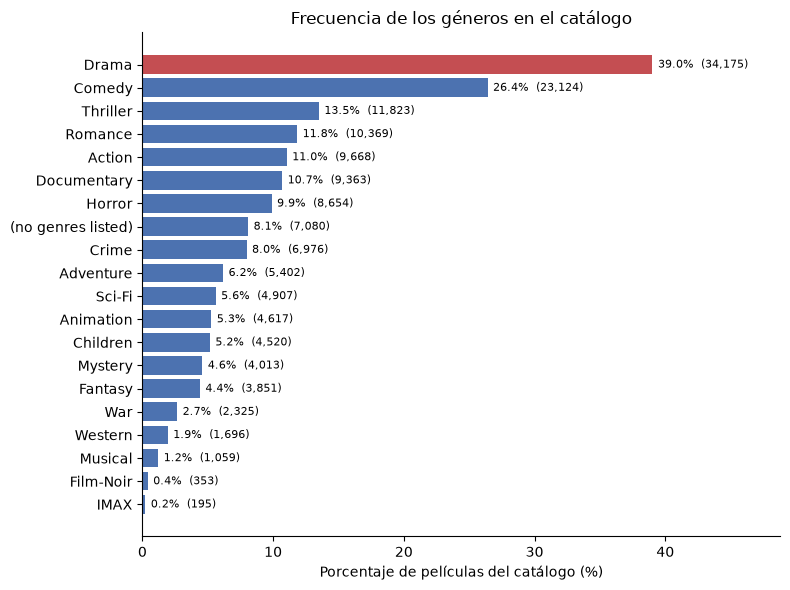

In [9]:

d = genre_frequency.sort_values("movie_count") 

colores = ["#C44E52" if g == "Drama" else "#4C72B0" for g in d["genre"]]

fig, ax = plt.subplots(figsize=(8, 6))
barras = ax.barh(d["genre"], d["catalog_pct"], color=colores)
ax.bar_label(
    barras,
    labels=[f"{p:.1f}%  ({n:,})" for p, n in zip(d["catalog_pct"], d["movie_count"])],
    padding=4, fontsize=8,
)

ax.set_xlim(0, d["catalog_pct"].max() * 1.25)   # espacio para las etiquetas
ax.set_xlabel("Porcentaje de películas del catálogo (%)")
ax.set_title("Frecuencia de los géneros en el catálogo")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretación.** El gráfico muestra qué proporción del catálogo pertenece a cada género. **Drama es el género más frecuente**, con **34, 175 películas (39%)**, seguido de **Comedy** (23,124; 26.4%), **Thriller** (11,823; 13.5%), **Romance** (10,369; 11.8%) y **Action** (9,668; 11.0%). A partir de ahí, los géneros ocupan una proporción cada vez menor del catálogo, hasta llegar a **IMAX** con 195 películas 0.2%.

Esto es relevante porque describe la composición de los datos antes de comparar calificaciones: los promedios de los géneros grandes se apoyan en miles de películas, mientras que los de los géneros pequeños se basan en pocas y son más inestables. También permite plantear la pregunta de la siguiente sección: si el género más frecuente es también el mejor calificado.

**Limitaciones.** Los porcentajes **no suman 100%**, porque una película puede tener varios géneros y se cuenta en cada uno de ellos. Por la misma razón.

### ¿Qué géneros reciben mejores calificaciones?

Para responder esta pregunta utilizamos la tabla `movies_consolidated`, que contiene, para cada película, su número de calificaciones y su calificación promedio. Como una película puede tener varios géneros, se cuenta dentro de cada uno de ellos.

Calculamos la calificación promedio de cada género, **ponderada por el número de calificaciones de cada película**
Los resultados se presentan en un gráfico de barras horizontales, ordenadas de mayor a menor promedio.


In [11]:
movies_rating_agg = movies_consolidated[["movieId", "rating_count", "rating_mean"]]
base = (
    movies_rating_agg.dropna(subset=["rating_mean"])
    .merge(movies_genres, on="movieId", how="left", validate="one_to_many")
)
base["suma"] = base["rating_mean"] * base["rating_count"]

res = base.groupby("genre").agg(
    n_peliculas=("movieId", "nunique"),
    n_calif=("rating_count", "sum"),
    media_peliculas=("rating_mean", "mean"),   # cada película pesa igual
    suma=("suma", "sum"),
)
res["media_ponderada"] = res["suma"] / res["n_calif"]   # cada calificación pesa igual
res = res.drop(columns="suma").sort_values("media_ponderada", ascending=False)


C:\Users\igpea\AppData\Local\Temp\ipykernel_36520\3485342901.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, loc="lower right")


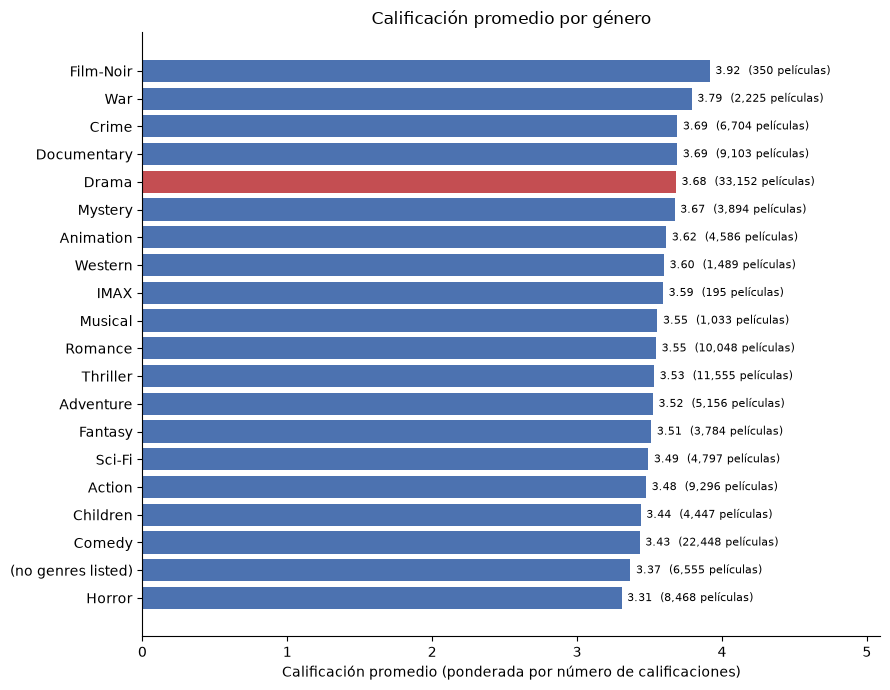

In [12]:
d = res.sort_values("media_ponderada") 

# Promedio de todas las calificaciones
validas = movies_rating_agg.dropna(subset=["rating_mean"])
promedio_general = (validas["rating_mean"] * validas["rating_count"]).sum() / validas["rating_count"].sum()

colores = ["#C44E52" if g == "Drama" else "#4C72B0" for g in d.index]

fig, ax = plt.subplots(figsize=(9, 7)) 
barras = ax.barh(d.index, d["media_ponderada"], color=colores)
ax.bar_label(
    barras,
    labels=[f"{m:.2f}  ({n:,} películas)" for m, n in zip(d["media_ponderada"], d["n_peliculas"])],
    padding=4, fontsize=8,
)


ax.set_xlim(0, d["media_ponderada"].max() * 1.3)   # espacio para las etiquetas
ax.set_xlabel("Calificación promedio (ponderada por número de calificaciones)")
ax.set_title("Calificación promedio por género")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretación.** El gráfico muestra la calificación promedio de cada género, ponderada por el número de calificaciones. **Film-Noir** tiene el promedio más alto (3.92), aunque es un género pequeño (350 películas), seguido de **War** (3.79). Después vienen Crime y Documentary, prácticamente empatados en 3.69, y Drama (3.68). En el extremo inferior están Horror (3.31), Comedy (3.43) y Children (3.44). Aun así, **las diferencias entre la mayoría de los géneros son moderadas**: casi todos se ubican entre 3.4 y 3.7.

El género más frecuente del catálogo (Drama) no es el mejor calificado, ocupa el quinto lugar. De hecho, los dos géneros con más películas terminan en posiciones muy distintas (Drama en el quinto lugar y Comedy en el 18.º de 19), por lo que la frecuencia de un género no parece asociarse con su calificación promedio.

**Limitaciones.** Una película con varios géneros se cuenta en cada uno de ellos, y al ponderar por número de calificaciones las películas muy vistas pesan más.
Los resultados son descriptivos y no permiten afirmar que un género cause mejores calificaciones.

### ¿Cómo se distribuye el promedio de calificaciones por género?

In [16]:
ratings.columns

Index(['userId', 'movieId', 'rating', 'timestamp'], dtype='object')

122129


C:\Users\igpea\AppData\Local\Temp\ipykernel_36520\3919387588.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(datos, vert=False, tick_labels=orden, showfliers=False)


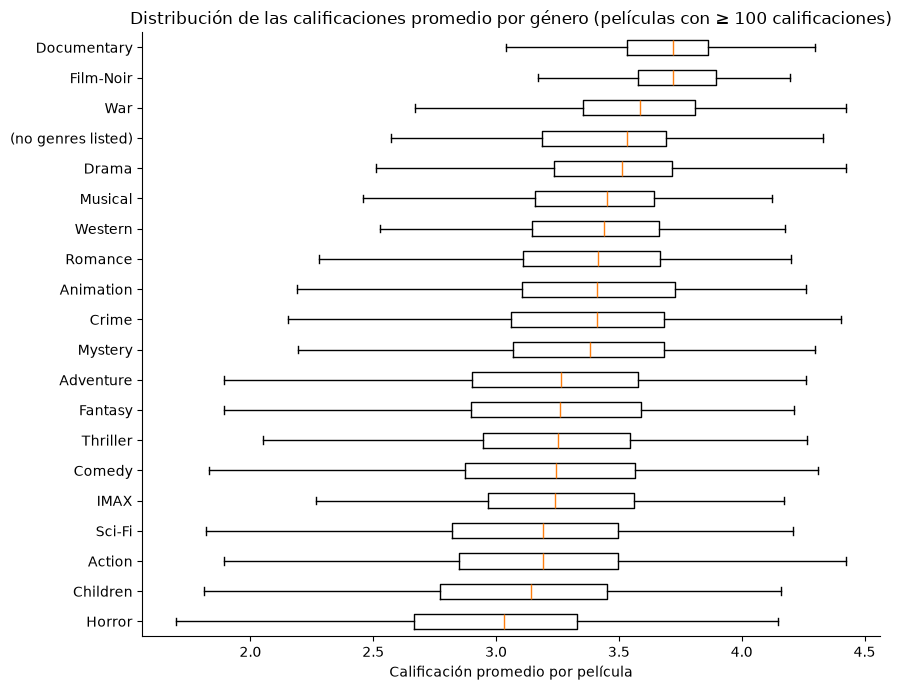

In [19]:
MIN_CALIF = 100
b = base[base["rating_count"] >= 100]
b_out = base[base["rating_count"] < 100]["movieId"].count()
print(b_out)
orden = b.groupby("genre")["rating_mean"].median().sort_values().index #ordena los género de menor a mayor mediana
datos = [b.loc[b["genre"] == g, "rating_mean"] for g in orden]

fig, ax = plt.subplots(figsize=(9, 7))
ax.boxplot(datos, vert=False, tick_labels=orden, showfliers=False)
ax.set_xlabel("Calificación promedio por película")
ax.set_title(f"Distribución de las calificaciones promedio por género (películas con ≥ {MIN_CALIF} calificaciones)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Interpretación.** El gráfico muestra, para cada género, cómo se distribuyen los promedios de calificación de sus películas. Film-Noir y Documentary tienen las medianas más altas (alrededor de 3.65), y Horror la más baja (cerca de 3.0). Film-Noir, además, presenta una de las cajas más angostas, por lo que sus películas son relativamente parecidas entre sí, mientras que Horror es uno de los géneros más dispersos, con películas desde promedios cercanos a 1.7 hasta más de 4.

Un hallazgo importante es que las cajas de los géneros con mejores calificaciones (Documentary y Film-Noir) no se traslapan con las demás. Por tanto,para estos dos géneros la pelicula típica si tiene un promedio distinto 

**Limitaciones.** Se grafican promedios por película, no calificaciones individuales, y cada película pesa igual sin importar su número de calificaciones. Se excluyeron las películas con menos de 100 calificaciones ([112129] películas), y no se muestran los valores atípicos. 

### ¿Cómo varían las calificaciones de las películas según su año de estreno?
Con el fin de evaluar si las películas clásicas reciben mejores calificaciones que las más recientes, extrajimos el año de estreno a partir del título, cuantificamos los registros faltantes y definimos qué hacer con ellos a partir de ese resultado.



In [20]:
sin_anio = movies_consolidated["year"].isna()

n_total = len(movies_consolidated)
n_sin_anio = int(sin_anio.sum())
print(f"{n_sin_anio:,} de {n_total:,} películas sin año ({sin_anio.mean():.2%})")

617 de 87,585 películas sin año (0.70%)


**617** películas no tienen un año registrado de estreno, lo cual representa el **0.70%** del total. Esto ocurre por una cuestión de formato: en esos casos el título no contiene el año entre paréntesis, de donde se extrajo la variable `year`. Como representan una fracción mínima del conjunto de datos, la decisión es eliminarlos antes de continuar con el análisis.

In [21]:
movies_consolidated_clean = movies_consolidated.dropna(subset=["year", "rating_mean"]).copy()
movies_consolidated_clean["decada"] = (movies_consolidated_clean["year"] // 10) * 10
movies_consolidated_clean["suma"] = movies_consolidated_clean["rating_mean"] * movies_consolidated_clean["rating_count"]
por_decada = movies_consolidated_clean.groupby("decada").agg(
    n_peliculas=("movieId", "nunique"),
    n_calif=("rating_count", "sum"),
    media_peliculas=("rating_mean", "mean"),   # cada película pesa igual
    suma=("suma", "sum"),
)
por_decada["media_ponderada"] = por_decada["suma"] / por_decada["n_calif"]   # cada calificación pesa igual
por_decada = por_decada.drop(columns="suma").sort_index()

Se excluyeron decadas con muy pocas peliculas ya que el promedio seria inestable

Décadas excluidas: [1870, 1880, 1890, 1900, 1910]


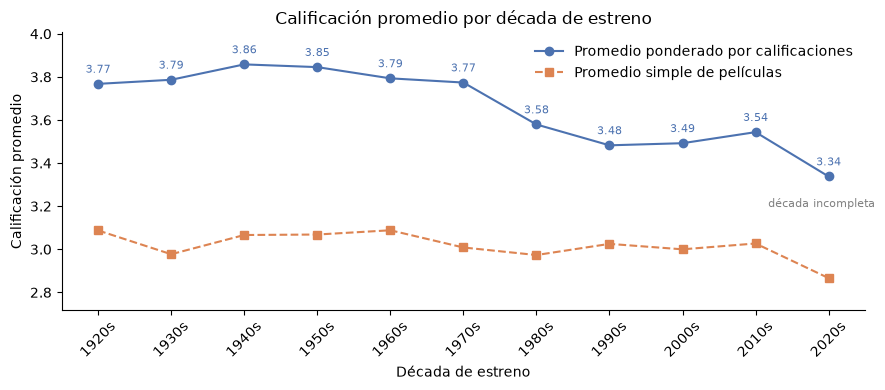

In [22]:
UMBRAL = 500 

d = por_decada.sort_index() #asigna un orden
d = d[d["n_peliculas"] >= 500]
print("Décadas excluidas:", por_decada.index.difference(d.index).tolist())

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(d.index, d["media_ponderada"], marker="o", color="#4C72B0",
        label="Promedio ponderado por calificaciones")
ax.plot(d.index, d["media_peliculas"], marker="s", linestyle="--", color="#DD8452",
        label="Promedio simple de películas")

# Valor sobre cada punto de la línea ponderada
for x, y in zip(d.index, d["media_ponderada"]):
    ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", color="#4C72B0", xytext=(0, 8),
                ha="center", fontsize=8,)

# Aviso si la última década está incompleta
if 2020 in d.index:
    ax.annotate("década incompleta", (2020, d.loc[2020, "media_ponderada"]),
                textcoords="offset points", xytext=(-5, -22), ha="center",
                fontsize=8, color="gray")

ax.set_xticks(d.index)
ax.set_xticklabels([f"{x}s" for x in d.index], rotation=45)
ax.margins(y=0.15)
ax.set_xlabel("Década de estreno")
ax.set_ylabel("Calificación promedio")
ax.set_title("Calificación promedio por década de estreno")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretación.** Al promediar las calificaciones ponderadas por el número de calificaciones, las películas estrenadas entre las décadas de 1920 y 1970 tienen promedios más altos (entre 3.77 y 3.86) que las estrenadas desde 1980 (entre 3.48 y 3.58), con un descenso adicional en la década de 2020 (3.34). Es decir, **las películas antiguas reciben mejores calificaciones que las recientes**, y la diferencia se concentra en un cambio entre los años setenta y ochenta, más que en una caída gradual.

Sin embargo, este resultado depende de cómo se promedie: el **promedio simple de las películas** apenas varía entre décadas (alrededor de 3.0), porque está dominado por títulos con pocas calificaciones. La diferencia aparece, por tanto, en las películas más vistas y calificadas, no en el catálogo en general.

**Limitaciones.** 
Las décadas anteriores a 1920 se excluyeron por tener muy pocos datos, y la década de 2020 está incompleta y sus películas han tenido menos tiempo para acumular calificaciones. **Los resultados son descriptivos: no permiten afirmar que la antigüedad de una película cause mejores calificaciones.**

### ¿Cómo se distribuye el número de calificaciones?

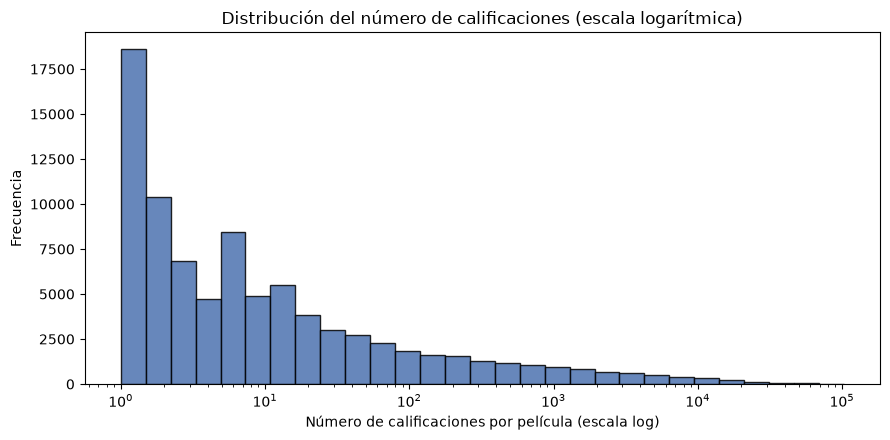

In [23]:

import numpy as np
import matplotlib.pyplot as plt

num_calificaciones = movies_consolidated["rating_count"].dropna()
positivos = num_calificaciones[num_calificaciones > 0]

bins = np.logspace(np.log10(positivos.min()), np.log10(positivos.max()), 30)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(positivos, bins=bins, color="#4C72B0", edgecolor="black", alpha=0.85)
ax.set_xscale("log")
ax.set(
    title="Distribución del número de calificaciones (escala logarítmica)",
    xlabel="Número de calificaciones por película (escala log)",
    ylabel="Frecuencia"
)
plt.tight_layout()
plt.show()

**Interpretación.** La gran mayoría de las películas reciben pocas calificaciones (por ejemplo, la mitad tiene 5 o menos y el 75% no supera las 23), mientras que solo las películas más populares alcanzan cientos o decenas de miles. Esto hace que la distribución esté sesgada hacia la derecha: muchas películas tienen muy pocas calificaciones y solo unas pocas reciben muchas. Se utiliza una escala logarítmica en el eje X para poder visualizar en una misma gráfica tanto los rangos bajos como los altos sin que los valores extremos aplasten el resto.

**Limitaciones.** 
Sólo se observan las películas que recibieron al menos una calificación (`rating_count > 0`), por lo que quedan fuera los títulos con 0 calificaciones o datos faltantes.

### ¿Cuál es el top 10 de las películas mejores calificadas?

In [24]:
top_ten_movies = movies_consolidated[movies_consolidated["rating_count"]>100].sort_values("rating_mean", ascending=False).head(10)

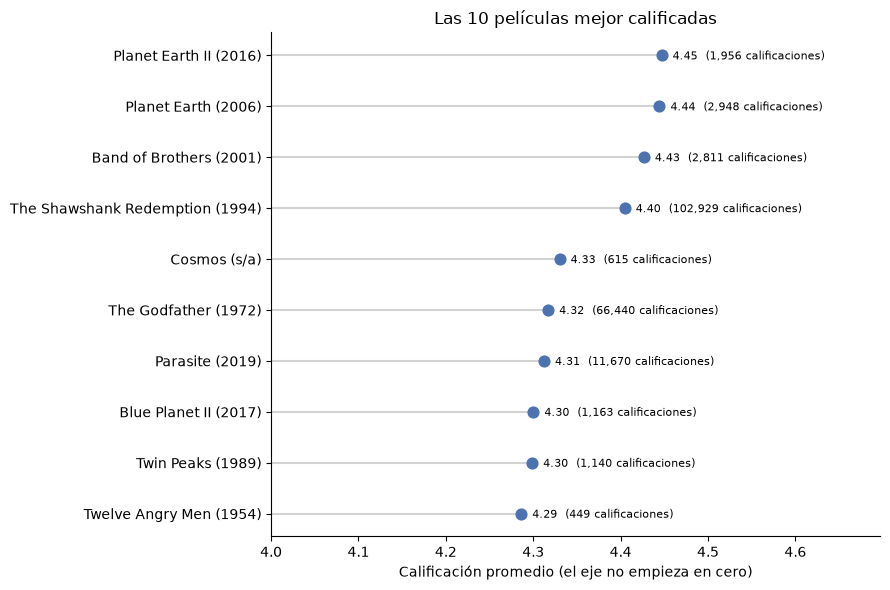

In [25]:

d = top_ten_movies.copy().sort_values("rating_mean")  

d["titulo"] = d["title_clean"].str.replace(r"^(.*), (The|A|An)$", r"\2 \1", regex=True)
anio = d["year"].apply(lambda y: f"{int(y)}" if pd.notna(y) else "s/a")
etiquetas = (d["titulo"] + " (" + anio + ")").tolist()

pos = range(len(d))
fig, ax = plt.subplots(figsize=(9, 6))
ax.hlines(pos, 4.0, d["rating_mean"], color="lightgray")
ax.scatter(d["rating_mean"], pos, color="#4C72B0", s=60, zorder=3)

for y, m, n in zip(pos, d["rating_mean"], d["rating_count"]):
    ax.annotate(f"{m:.2f}  ({n:,} calificaciones)", (m, y),
                textcoords="offset points", xytext=(8, -3), fontsize=8)

ax.set_yticks(list(pos))
ax.set_yticklabels(etiquetas)
ax.set_xlim(4.0, d["rating_mean"].max() + 0.25)
ax.set_xlabel("Calificación promedio (el eje no empieza en cero)")
ax.set_title("Las 10 películas mejor calificadas")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretación.** El gráfico muestra las diez películas con mayor calificación promedio entre las que tienen al menos 500 calificaciones. Los promedios van de [4.27] a [4.45]. Predominan los géneros Documentary y Drama, y se mezclan títulos de épocas muy distintas, desde 1957 hasta 2019. Además, algunos títulos con promedio alto tienen relativamente pocas calificaciones (por ejemplo, [Cosmos con 615]), mientras que otros, como *The Shawshank Redemption*, superan las 100,000.

**Limitaciones.** El ranking depende del mínimo de calificaciones elegido, y con otro umbral podrían entrar o salir títulos.

### ¿Cuál es el top 10 de las películas con más calificaciones?

In [27]:
top_ten_movies_count = movies_consolidated[movies_consolidated["rating_count"]>100].sort_values("rating_count", ascending=False).head(10)

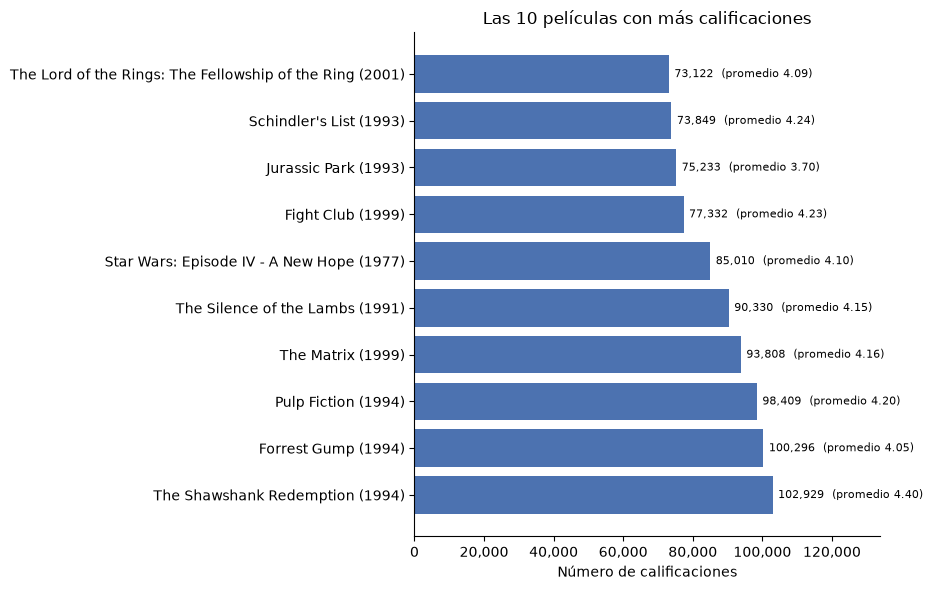

In [28]:

d = top_ten_movies_count.head(10).copy() 

d["titulo"] = d["title_clean"].str.replace(r"^(.*), (The|A|An)$", r"\2 \1", regex=True)
anio = d["year"].apply(lambda y: f"{int(y)}" if pd.notna(y) else "s/a")
etiquetas = (d["titulo"] + " (" + anio + ")").tolist()

fig, ax = plt.subplots(figsize=(9, 6))
barras = ax.barh(etiquetas, d["rating_count"], color="#4C72B0")
ax.bar_label(
    barras,
    labels=[f"{n:,}  (promedio {m:.2f})" for n, m in zip(d["rating_count"], d["rating_mean"])],
    padding=4, fontsize=8,
)

ax.set_xlim(0, d["rating_count"].max() * 1.3)   # espacio para las etiquetas
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_xlabel("Número de calificaciones")
ax.set_title("Las 10 películas con más calificaciones")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

**Interpretación.** La película con más calificaciones es *The Shawshank Redemption* (1994), con **102,929**, seguida de *Forrest Gump* (1994) con **100,296** y *Pulp Fiction* (1994) con **98,409**. Un patrón destacable es que **ocho de las diez películas** más calificadas se estrenaron en la década de 1990; las otras dos son *Star Wars: Episode IV* (1977) y *The Lord of the Rings: The Fellowship of the Ring* (2001).

Todas estas películas tienen promedios altos, entre **3.70** (*Jurassic Park*) y **4.40** (*The Shawshank Redemption*), pero la película más calificada no es la de promedio más alto en todos los casos: por ejemplo, *Forrest Gump* tiene 4.05 y *Schindler's List*, con menos calificaciones, tiene 4.24. Es decir, el **número de calificaciones (popularidad)** y la **calificación promedio (valoración)** miden cosas distintas.

**Limitaciones.** Estas diez películas son una fracción mínima del catálogo, donde la mayoría tiene pocas calificaciones, por lo que no representan al resto.